<a href="https://colab.research.google.com/github/ArbiHuy/ADY-Coursera/blob/main/_Optional_Peer_Graded_Assignment_jupyterlite_v2_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center>
    <img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/Logos/organization_logo/organization_logo.png" width="300" alt="cognitiveclass.ai logo">
</center>


#### Import the required libraries we need for the lab.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL


In [2]:
boston_df=pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv')

#### Add your code below following the instructions given in the course to complete the peer graded assignment


In [3]:
boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


In [4]:
boston_df.info()
boston_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  506 non-null    int64  
 1   CRIM        506 non-null    float64
 2   ZN          506 non-null    float64
 3   INDUS       506 non-null    float64
 4   CHAS        506 non-null    float64
 5   NOX         506 non-null    float64
 6   RM          506 non-null    float64
 7   AGE         506 non-null    float64
 8   DIS         506 non-null    float64
 9   RAD         506 non-null    float64
 10  TAX         506 non-null    float64
 11  PTRATIO     506 non-null    float64
 12  LSTAT       506 non-null    float64
 13  MEDV        506 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 55.5 KB


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


### Task 1: Boxplot for the "Median value of owner-occupied homes" (MEDV)

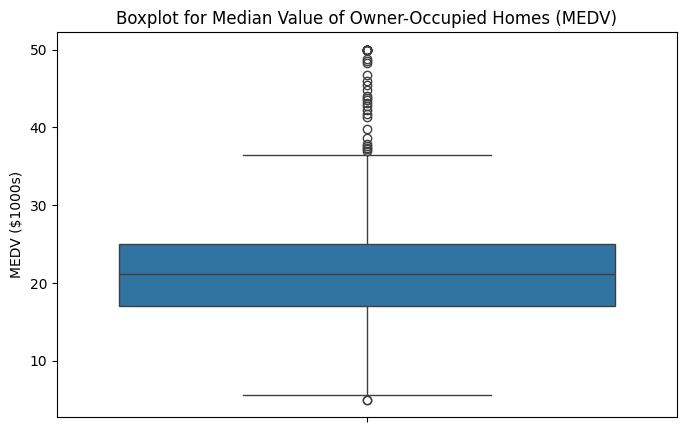

In [5]:
pyplot.figure(figsize=(8, 5))
ax = sns.boxplot(y='MEDV', data=boston_df)
pyplot.title('Boxplot for Median Value of Owner-Occupied Homes (MEDV)')
pyplot.ylabel('MEDV ($1000s)')
pyplot.show()

In [ ]:
**Explanation:** The boxplot shows that the median home value (MEDV) is around $21,200 (21.2 in $1000s), with several high-value outliers above $35,000 up to the $50,000 cap.

### Task 2: Bar plot for the Charles River variable (CHAS)

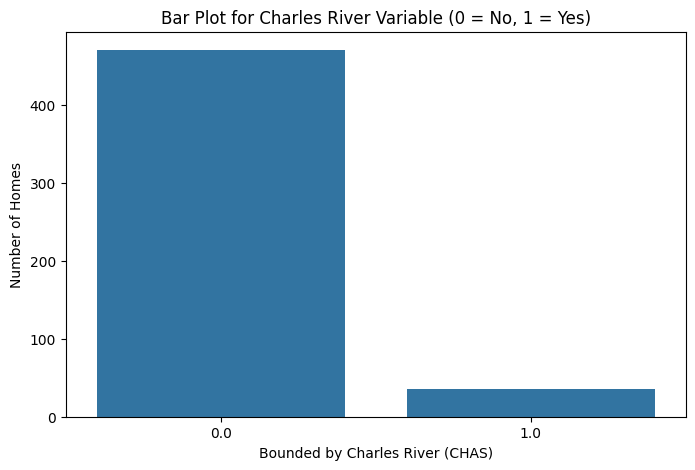

In [6]:
pyplot.figure(figsize=(8, 5))
sns.countplot(x='CHAS', data=boston_df)
pyplot.title('Bar Plot for Charles River Variable (0 = No, 1 = Yes)')
pyplot.xlabel('Bounded by Charles River (CHAS)')
pyplot.ylabel('Number of Homes')
pyplot.show()

**Explanation:** The vast majority of tracts (471 out of 506) do not bound the Charles River (`CHAS = 0`), while only 35 tracts bound the river (`CHAS = 1`).

### Task 3: Boxplot for the MEDV variable vs the AGE variable (Discretized into three age groups)

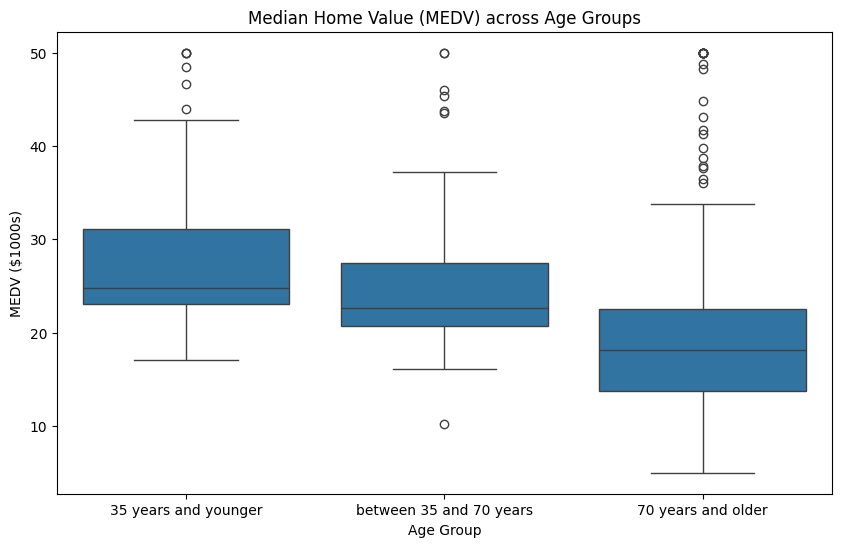

In [7]:
boston_df.loc[(boston_df['AGE'] <= 35), 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70 years'
boston_df.loc[(boston_df['AGE'] >= 70), 'age_group'] = '70 years and older'

pyplot.figure(figsize=(10, 6))
sns.boxplot(x='age_group', y='MEDV', data=boston_df,
            order=['35 years and younger', 'between 35 and 70 years', '70 years and older'])
pyplot.title('Median Home Value (MEDV) across Age Groups')
pyplot.xlabel('Age Group')
pyplot.ylabel('MEDV ($1000s)')
pyplot.show()

**Explanation:** Newer houses (35 years and younger) have a noticeably higher median value compared to older houses, while homes aged 70 years and older have the lowest median value.

### Task 4: Scatter plot to show the relationship between Nitric oxide concentrations (NOX) and the proportion of non-retail business acres per town (INDUS)

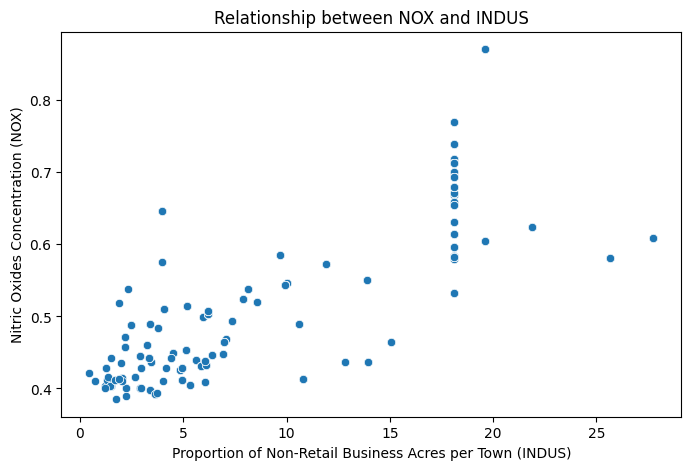

In [8]:
pyplot.figure(figsize=(8, 5))
sns.scatterplot(x='INDUS', y='NOX', data=boston_df)
pyplot.title('Relationship between NOX and INDUS')
pyplot.xlabel('Proportion of Non-Retail Business Acres per Town (INDUS)')
pyplot.ylabel('Nitric Oxides Concentration (NOX)')
pyplot.show()

**Explanation:** There is a strong positive relationship between `INDUS` and `NOX`. As the proportion of non-retail business acres increases, nitric oxide concentration increases upward until `INDUS` reaches around 18–20.

### Task 5: Histogram for the pupil to teacher ratio variable (PTRATIO)

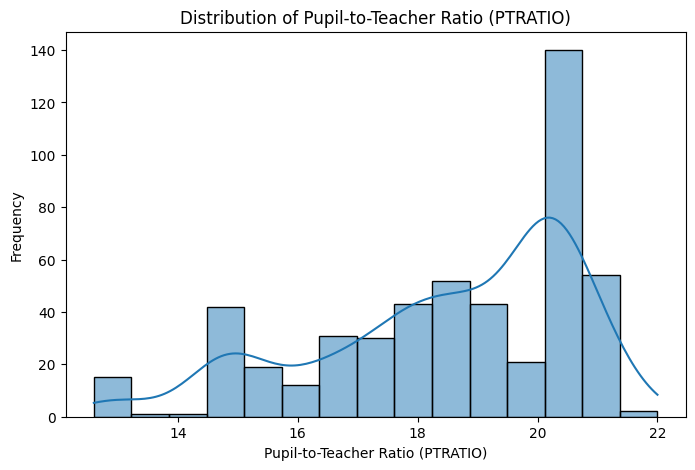

In [9]:
pyplot.figure(figsize=(8, 5))
sns.histplot(boston_df['PTRATIO'], kde=True, bins=15)
pyplot.title('Distribution of Pupil-to-Teacher Ratio (PTRATIO)')
pyplot.xlabel('Pupil-to-Teacher Ratio (PTRATIO)')
pyplot.ylabel('Frequency')
pyplot.show()

**Explanation:** The distribution of `PTRATIO` is left-skewed, with the highest spike occurring around a ratio of 20.2 pupils per teacher.

### Question 1: Is there a significant difference in median value of houses bounded by the Charles river or not? (T-test for independent samples)
* **$H_0$ (Null Hypothesis):** $\mu_1 = \mu_2$ (There is no significant difference in median value of houses bounded by the Charles river and those not bounded).
* **$H_1$ (Alternative Hypothesis):** $\mu_1 \neq \mu_2$ (There is a significant difference in median value of houses bounded by the Charles river).
* Significance level: $\alpha = 0.05$

In [10]:
# Levene's Test for equality of variance
levene_stat, levene_p = scipy.stats.levene(boston_df[boston_df['CHAS'] == 0]['MEDV'],
                                           boston_df[boston_df['CHAS'] == 1]['MEDV'], center='mean')
print(f"Levene's Test: statistic = {levene_stat:.4f}, p-value = {levene_p:.6f}")

# Independent two-sample t-test
t_stat, p_val = scipy.stats.ttest_ind(boston_df[boston_df['CHAS'] == 0]['MEDV'],
                                      boston_df[boston_df['CHAS'] == 1]['MEDV'], equal_var=True)
print(f"T-test (equal_var=True): t-statistic = {t_stat:.4f}, p-value = {p_val:.6f}")

t_stat_welch, p_val_welch = scipy.stats.ttest_ind(boston_df[boston_df['CHAS'] == 0]['MEDV'],
                                                  boston_df[boston_df['CHAS'] == 1]['MEDV'], equal_var=False)
print(f"Welch's T-test (equal_var=False): t-statistic = {t_stat_welch:.4f}, p-value = {p_val_welch:.6f}")

Levene's Test: statistic = 8.7519, p-value = 0.003238
T-test (equal_var=True): t-statistic = -3.9964, p-value = 0.000074
Welch's T-test (equal_var=False): t-statistic = -3.1133, p-value = 0.003567


**Conclusion:** Since the p-value ($0.000074$ with `equal_var=True`, or $0.003567$ with `equal_var=False`) is less than $\alpha = 0.05$, we **reject the null hypothesis ($H_0$)**. There is a statistically significant difference in median home values between houses bounded by the Charles River and those that are not.

### Question 2: Is there a difference in Median values of houses (MEDV) for each proportion of owner occupied units built prior to 1940 (AGE)? (ANOVA)
* **$H_0$ (Null Hypothesis):** $\mu_1 = \mu_2 = \mu_3$ (The three population means across the age groups are equal).
* **$H_1$ (Alternative Hypothesis):** At least one of the age group means differs significantly.
* Significance level: $\alpha = 0.05$

In [11]:
thirtyfive_lower = boston_df[boston_df['age_group'] == '35 years and younger']['MEDV']
thirtyfive_seventy = boston_df[boston_df['age_group'] == 'between 35 and 70 years']['MEDV']
seventy_older = boston_df[boston_df['age_group'] == '70 years and older']['MEDV']

f_statistic, p_value = scipy.stats.f_oneway(thirtyfive_lower, thirtyfive_seventy, seventy_older)
print(f"F-Statistic: {f_statistic:.4f}, P-Value: {p_value:.6e}")

F-Statistic: 36.4076, P-Value: 1.710501e-15


**Conclusion:** Since the p-value ($1.7105 \times 10^{-15}$) is less than $\alpha = 0.05$, we **reject the null hypothesis ($H_0$)**. There is a statistically significant difference in median home values (`MEDV`) across the three age groups.

### Question 3: Can we conclude that there is no relationship between Nitric oxide concentrations (NOX) and proportion of non-retail business acres per town (INDUS)? (Pearson Correlation)
* **$H_0$ (Null Hypothesis):** $r = 0$ (There is no linear correlation between `NOX` and `INDUS`).
* **$H_1$ (Alternative Hypothesis):** $r \neq 0$ (There is a significant linear correlation between `NOX` and `INDUS`).
* Significance level: $\alpha = 0.05$

In [12]:
r_stat, p_val_corr = scipy.stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])
print(f"Pearson Correlation Coefficient (r): {r_stat:.4f}, P-Value: {p_val_corr:.6e}")

Pearson Correlation Coefficient (r): 0.7637, P-Value: 7.913361e-98


**Conclusion:** Since the p-value ($7.9134 \times 10^{-98}$) is less than $\alpha = 0.05$, we **reject the null hypothesis ($H_0$)**. There is a strong positive linear relationship ($r = 0.7637$) between nitric oxide concentrations (`NOX`) and the proportion of non-retail business acres (`INDUS`).

### Question 4: What is the impact of an additional weighted distance to the five Boston employment centres (DIS) on the median value of owner occupied homes (MEDV)? (Regression Analysis)
* **$H_0$ (Null Hypothesis):** $\beta_1 = 0$ (`DIS` has no significant impact on `MEDV`).
* **$H_1$ (Alternative Hypothesis):** $\beta_1 \neq 0$ (`DIS` has a statistically significant impact on `MEDV`).
* Significance level: $\alpha = 0.05$

In [13]:
X = boston_df['DIS']
y = boston_df['MEDV']
X = sm.add_constant(X)

model = sm.OLS(y, X).fit()
predictions = model.predict(X)
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        11:21:23   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

**Conclusion:** Since the p-value ($1.21 \times 10^{-8}$) is less than $\alpha = 0.05$, we **reject the null hypothesis ($H_0$)**. The coefficient for `DIS` is **1.0916**, indicating that for each additional unit of weighted distance to the five Boston employment centres, the median value of owner-occupied homes (`MEDV`) increases by **1.0916** (or **$1,091.60**). Furthermore, $R = \sqrt{0.062} \approx 0.249$ shows a positive correlation.